<table>
<tr><td><img style="height: 150px;" src="images/geo_hydro1.jpg"></td>
<td bgcolor="#FFFFFF">
    <p style="font-size: xx-large; font-weight: 900; line-height: 100%">pyRANDOM</p>
    <p style="font-size: large; color: rgba(0,0,0,0.5);"><b style=color:red;>RANDOM</b> <b style=color:red;>NUMBERS</b></p>
    <p style="font-size: large; color: rgba(0,0,0,0.5);">Georg Kaufmann</p>
    </td>
<td><img style="height: 150px;" src="images/pyRANDOM.png"></td>
</tr>
</table>

----
# `pyRANDOM`

pyRANDOM, a collection of jupyter notebooks playing with **random numbers** ...

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import itertools
import libpyRANDOM

----
# Traveling salesman problem: Permutations
In this notebook, we try to find the **shortest path** between all nodes, based
on **permutations**.

First, we use the library `libpyRANDOM` with our previously discussed functions and create
**node arrays** `x`,  `y`,  and `cities`, and the **distance matrix** `matrix`, 
and correct for the not wanted pathes: 

In [2]:
x,y,cities = libpyRANDOM.tspSetupCoordinatesSquare()
matrix = libpyRANDOM.tspCreateDistanceMatrix(x,y)
matrix[0][2] = np.nan
matrix[2][0] = np.nan
matrix[1][3] = np.nan
matrix[3][1] = np.nan
print(matrix)

[[0.         2.                nan 2.         1.56204994]
 [2.         0.         2.                nan 1.28062485]
 [       nan 2.         0.         2.         1.28062485]
 [2.                nan 2.         0.         1.56204994]
 [1.56204994 1.28062485 1.28062485 1.56204994 0.        ]]


Check, if is looks correct:

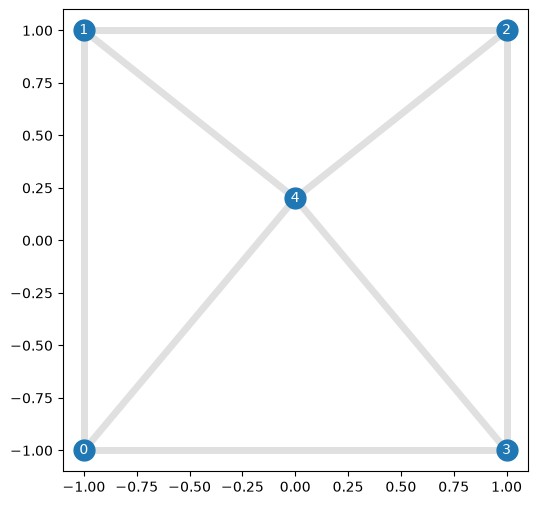

In [3]:
plt.figure(figsize=(6,6))
plt.xlim([-1.1,1.1])
plt.ylim([-1.1,1.1])
# plot all distances
for i in range(matrix.shape[0]):
        for j in range(i+1,matrix.shape[0]):
            if (np.isfinite(matrix[i][j])):
                plt.plot([x[i],x[j]],[y[i],y[j]],lw=5,alpha=0.7,color='lightgray')
# plot nodes
plt.plot(x,y,lw=0,marker='o',markersize=15)
for i in range(len(x)):
    plt.text(x[i],y[i],str(cities[i]),ha='center',va='center',color=(1,1,1))

----
## Permutations
We have the list of nodes in the array `cities`, which in our case is `0,1,2,3,4`. 
This list describes one path, which we defined simply during the creation of the array.

If we want to test **all** possible pathes, we need to rearrange the array `cities` to
get all combinations of the cities, as all cities are connected (at least for the monent ...).

We use **permutations** to sample the entire range of possibilities. 

```
A permutation describes the different possibilities to order
a set of elements in a list, e.g. points in an array.
```

Examples:

`(1,2)` has the permutations `(1,2), (2,1)`

`(1,2,3)` has the permutations `(1, 2, 3), (1, 3, 2), (2, 1, 3), (2, 3, 1), (3, 1, 2), (3, 2, 1)`

`(A,B,C)` has the permutations `(A,B,C),(A,C,B),(B,A,C),(B,C,A),(C,A,B),(C,B,A)`


For $N$ cities, with the $N=0$ city
fixed as starting point, we will find $(N-1)!$ permutations of our array.

In our example, with $N=5$ nodes, fixing the first node `0` as starting point, we will get
$4!=24$ different ways to arrange the list of nodes.

We use command `permutations` from the `itertools` package.
Note that we hand down the ordered list `cities` except its first element (0), as we keep this
fixed as starting point (and later as end point, too).

In [4]:
print(cities)
N = x.shape[0]
perm = itertools.permutations(cities[1:], N-1)
# loop over permutations
for order in list(perm):
    print(order)
#perm = itertools.permutations(cities[1:], N-1)
for order in list(perm):
    print(order)

[0 1 2 3 4]
(np.int64(1), np.int64(2), np.int64(3), np.int64(4))
(np.int64(1), np.int64(2), np.int64(4), np.int64(3))
(np.int64(1), np.int64(3), np.int64(2), np.int64(4))
(np.int64(1), np.int64(3), np.int64(4), np.int64(2))
(np.int64(1), np.int64(4), np.int64(2), np.int64(3))
(np.int64(1), np.int64(4), np.int64(3), np.int64(2))
(np.int64(2), np.int64(1), np.int64(3), np.int64(4))
(np.int64(2), np.int64(1), np.int64(4), np.int64(3))
(np.int64(2), np.int64(3), np.int64(1), np.int64(4))
(np.int64(2), np.int64(3), np.int64(4), np.int64(1))
(np.int64(2), np.int64(4), np.int64(1), np.int64(3))
(np.int64(2), np.int64(4), np.int64(3), np.int64(1))
(np.int64(3), np.int64(1), np.int64(2), np.int64(4))
(np.int64(3), np.int64(1), np.int64(4), np.int64(2))
(np.int64(3), np.int64(2), np.int64(1), np.int64(4))
(np.int64(3), np.int64(2), np.int64(4), np.int64(1))
(np.int64(3), np.int64(4), np.int64(1), np.int64(2))
(np.int64(3), np.int64(4), np.int64(2), np.int64(1))
(np.int64(4), np.int64(1), np.int6

In the above list of 24 arrangements, there are always pathes, which we excluded before, which we have to
address in the following function.

We perform the following steps:
- loop over all permutations
- create a closed loop by adding `0` as start and as end point
- sum up all distances in the variable `total_dist`
- exclude loops with non-existing pathes by setting dist to `np.inf`
- check if the calculated variable `total_dist` is smaller than the current `total_dist_min`

In [5]:
def tspPermutation(cities,matrix):
    """
    Solve traveling-salesmen problem
    version with permutations
    input:
      cities - list of names for points
      matrix - matrix of distances between two points
    output:
      total_dist_min [m] - minimum distance
      total_dist_max [m] - maximum distance
      minorder           - list of points of shortest path
    """
    # get number of cities
    N = cities.shape[0]
    print(cities)
    # create all permutations for distances
    perm = itertools.permutations(cities[1:], N-1)
    # start loop over permutations
    icount         = 0
    total_dist_min = np.inf
    total_dist_max = 0.
    # loop over permutations
    for order in list(perm):
        icount += 1
        # add start/end as zero index
        neworder = (0,)+order+(0,)
        #print (neworder,type(neworder),len(neworder))
        total_dist = 0.
        # calculate total_dist, exclude "infinite" connections
        for i in range(len(neworder)-1):
            if (np.isnan(matrix[neworder[i]][neworder[i+1]])):
                dist = np.inf
            else:
                dist = matrix[neworder[i]][neworder[i+1]]
            total_dist += dist
        # check if total_dist is smallest value
        #minorder = 0.
        if (total_dist < total_dist_min):
            total_dist_min = total_dist
            minorder = neworder
        if (total_dist > total_dist_max and total_dist != np.inf):
            total_dist_max = total_dist
    # Best result
    print('min path: ',total_dist_min)
    print('max path: ',total_dist_max)
    print('best path: ',minorder,icount)
    return total_dist_min,total_dist_max,minorder

In [6]:
total_dist_min,total_dist_max,minorder = tspPermutation(cities,matrix)
print(minorder)

[0 1 2 3 4]
min path:  8.561249694973139
max path:  9.124099870362661
best path:  (0, np.int64(1), np.int64(4), np.int64(2), np.int64(3), 0) 24
(0, np.int64(1), np.int64(4), np.int64(2), np.int64(3), 0)


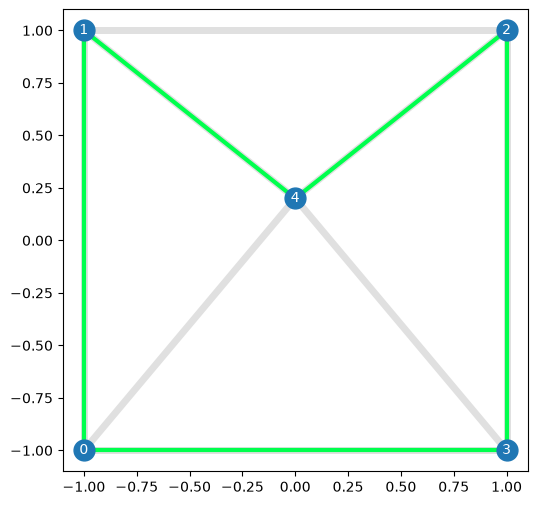

In [7]:
plt.figure(figsize=(6,6))
plt.xlim([-1.1,1.1])
plt.ylim([-1.1,1.1])
# plot all distances
for i in range(matrix.shape[0]):
        for j in range(i+1,matrix.shape[0]):
            if (np.isfinite(matrix[i][j])):
                plt.plot([x[i],x[j]],[y[i],y[j]],lw=5,alpha=0.7,color='lightgray')
# plot shortest distance
for i in range(1,len(minorder)):
            plt.plot([x[minorder[i-1]],x[minorder[i]]],[y[minorder[i-1]],y[minorder[i]]],lw=3,color=(0.0,1.0,0.3))
# plot nodes
plt.plot(x,y,lw=0,marker='o',markersize=15)
for i in range(len(x)):
    plt.text(x[i],y[i],str(cities[i]),ha='center',va='center',color=(1,1,1))

The resulting **shortest path** is [0,1,4,2,3], as the point `4`is slightly offset in $y$ direction towards the north.

----